# verdicts on r/amitheasshole: text preparation, topics, and men vs women

people post a personal conflict on r/amitheasshole and commenters vote on a verdict. this notebook keeps the two clear-cut verdicts: **nta** ("not the asshole") and **yta** ("you're the asshole"). the data are 270,709 posts from 2013 to april 2023 (Bsher and Sabri 2023, *AITA Generating Moral Judgements of the Crowd with Reasoning*, arXiv:2310.18336, [huggingface.co/datasets/OsamaBsher/AITA-Reddit-Dataset](https://huggingface.co/datasets/OsamaBsher/AITA-Reddit-Dataset)). 250,487 of them have an nta or yta verdict, and this notebook uses a random sample of 50,000 of those, of which about 19% are yta.

it answers three questions:

1. **text preparation.** how well can the verdict be predicted from the text of the post, and how much does that depend on how the text is prepared?
2. **topics.** do topics differ in how often they end in yta, and how much of the prediction is just topic?
3. **men and women.** do narrators who say they are men and narrators who say they are women write about different topics, and are they judged differently, including within the same topic?

the text preparation choices are:

- **tokenizer**: how a post is split into words (`whitespace`, `regex`, `treebank`)
- **normalizer**: how the vocabulary is shrunk (`none`, remove common words, cut words to a stem, or both)
- **representation**: how words become numbers (word counts, tf-idf weights, or a sentence embedding)

hypotheses, all two-sided (they ask whether groups differ, not in which direction):

| | hypothesis | posts used |
|---|---|---|
| h1 | men and women write about different topics | posts where the narrator stated a gender |
| h2 | men and women get yta at different rates | same |
| h3 | they still get yta at different rates within the same topic | same |
| h4 | topics differ in how often they end in yta | all 50,000 posts |

this notebook only reads the tables written by `python -m scripts.run`.

In [1]:
import sys
import pandas as pd
sys.path.insert(0, '..')                  # makes the project's scripts/ folder importable
from scripts import plots                 # one function per figure
pd.set_option('display.max_colwidth', 80)

read = lambda f: pd.read_csv(f'../results/{f}')
grid, topics, hyp, topic_only = read('grid.csv'), read('topics.csv'), read('hypotheses.csv'), read('topic_only.csv')
mix, verdicts = read('topic_mix.csv'), read('topic_verdicts.csv')    # per topic: men vs women, in what they write and how they are judged
by_topic, by_length = read('by_topic_name.csv'), read('by_length.csv')
pred = read('predictions.csv')                                       # one row per post, with the predicted probability of yta (p)
overall = pred.y.mean()
print(f'{len(pred)} posts, {overall:.1%} yta, narrator gender stated in {pred.gender.notna().mean():.0%}')

50000 posts, 19.0% yta, narrator gender stated in 31%


## 1. how text preparation affects prediction

the same classifier (logistic regression) is used for every combination, so differences in score come only from how the text is prepared. each post is predicted by a model that never saw it (5-fold cross-validation), so all 50,000 posts count as test data.

the score is the **area under the roc curve (auc)**: the chance that a random yta post gets a higher predicted probability of yta than a random nta post. 0.5 means guessing and 1.0 means perfect. the bars are 95% intervals from resampling the posts 200 times, showing how much the score would change with a different set of posts. **combinations whose bars overlap cannot be told apart.**

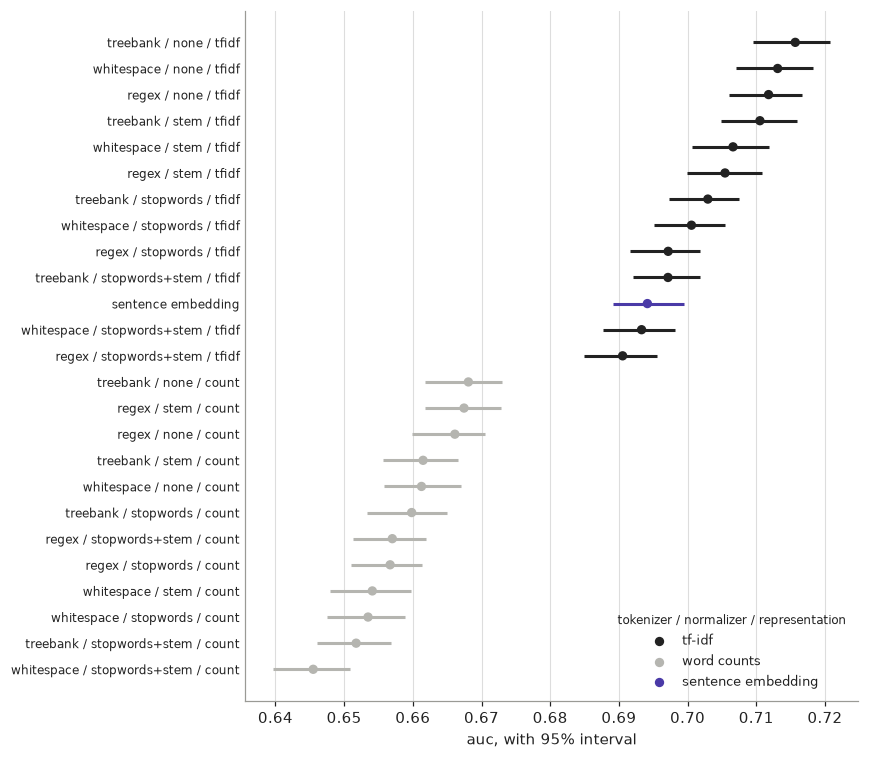

In [2]:
plots.pipelines(grid)

**what it shows.** the labels read tokenizer / normalizer / representation.

- **representation matters most.** tf-idf (auc 0.69 to 0.72) is clearly ahead of raw word counts (0.65 to 0.67), and the sentence embedding (0.69) falls in between. counts lose because a long post has large counts for every word, so counts partly measure how much was written, while tf-idf rescales each post and down-weights words that appear everywhere.
- **the tokenizer makes almost no difference.** with no normalization and tf-idf, whitespace, regex and treebank score 0.712 to 0.716, and their bars overlap.
- **removing common words costs a little.** with tf-idf, leaving the text alone scores 0.712 to 0.716 and removing stopwords 0.697 to 0.703, and the bars do not overlap. cutting words to a stem costs less (0.705 to 0.711), and doing both is lowest (0.691 to 0.697). a likely reason is that words like *i*, *you* and *my* show who is blaming whom, so deleting them removes information.
- **the best score is about 0.72.** the verdict is partly predictable from the text, not mostly.

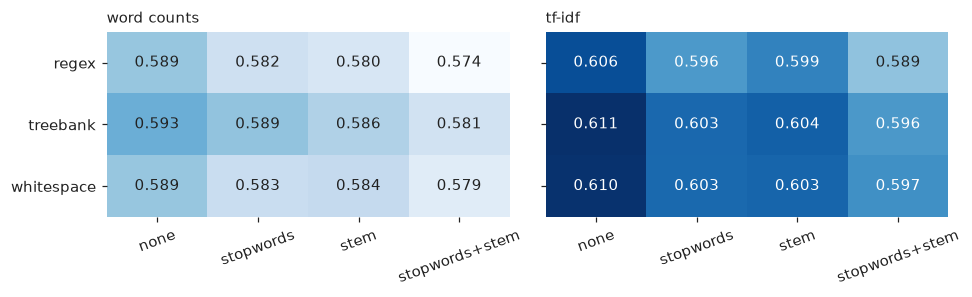

In [3]:
plots.macro_f1_grid(grid)

**what it shows.** the same comparison using macro-f1, which averages how well nta and yta posts are classified, so it is not inflated by nta being the majority. rows are tokenizers, columns are normalizers, and darker is better. the pattern matches the figure above: the rows look alike (the tokenizer barely matters), the `none` column is darkest, and tf-idf is darker than word counts. the 95% interval for each cell is roughly plus or minus 0.005, so gaps of about 0.01 or more between cells are probably real, and smaller gaps are not.

## 2. topics

latent dirichlet allocation (lda) groups words that tend to appear in the same posts into topics. it never sees the verdict or the narrator's gender. each post is assigned its most likely topic. each topic is named by its number and its three most likely words.

In [4]:
topics[['name', 'share', 'top_words']]

,name,share,top_words
0,0: money/pay/job,0.085,"money, pay, job, paid, paying, buy, help, years"
1,1: work/job/working,0.067,"work, job, working, day, week, manager, boss, company"
2,2: cat/sleep/night,0.032,"cat, sleep, night, bed, hair, morning, home, day"
3,3: food/eat/car,0.046,"food, eat, car, drive, dinner, make, eating, home"
4,4: kids/husband/wife,0.057,"kids, husband, wife, daughter, son, baby, child, family"
5,5: wedding/sister/family,0.040,"wedding, sister, family, fiancé, married, wear, dress, asked"
6,6: phone/watch/door,0.042,"phone, watch, door, asked, watching, house, neighbor, movie"
7,7: friend/friends/relationship,0.123,"friend, friends, relationship, years, boyfriend, ex, best, months"
8,8: school/help/bad,0.065,"school, help, bad, health, sister, things, mom, started"
9,9: friend/car/friends,0.073,"friend, car, friends, went, asked, people, guy, did"


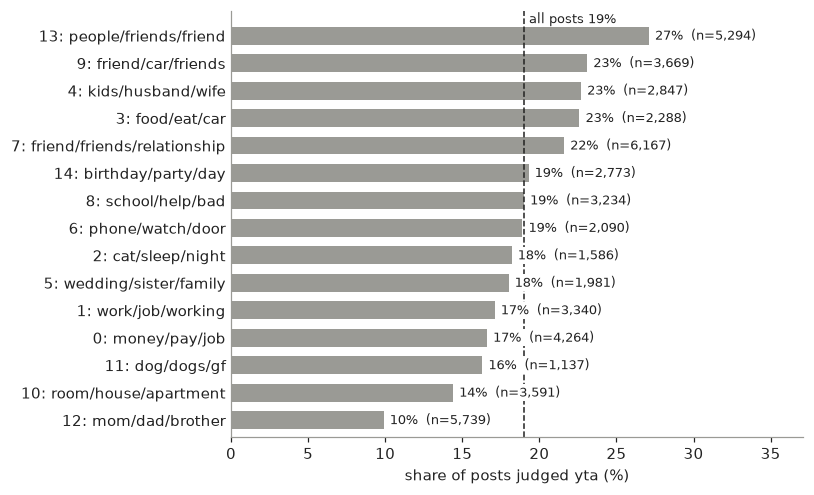

In [5]:
plots.yta_by_topic(by_topic, overall)

**what it shows.** (h4) what a story is about changes how often the verdict is yta. the mom/dad/brother topic sits near 10% and room/house/apartment near 14%, while the people/friends/friend topic reaches 27% and several others (friend/car/friends, kids/husband/wife, food/eat/car) are around 23%. a chi-square test across the 15 topics gives p < 0.001 and cramer's v of about 0.12 (see the hypothesis table at the end of section 3). every bar has more than a thousand posts behind it.

how much of the prediction is topic alone? the chart below compares two models on all 50,000 posts: one that sees only which topic a post belongs to (no words, no gender), and the full text model from section 1.

topic alone gives 38% of the full text model's improvement over guessing


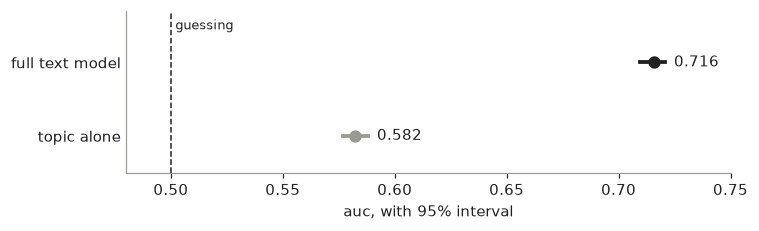

In [6]:
plots.topic_only(topic_only)
share = topic_only.set_index('model').share_of_lift['topic alone']
print(f"topic alone gives {share:.0%} of the full text model's improvement over guessing")

**what it shows.** knowing only the topic gives auc about 0.58, against 0.72 for the full text model. topic alone therefore accounts for about 38% of the model's improvement over guessing. the other 62% comes from the words themselves, so the model is reading more than the subject of the post.

## 3. men and women

only posts where the narrator stated their gender (like *"22f"* or *"m 35"* in the title) can be used here, about 31% of the sample (15,682 posts: 10,094 women, 5,588 men). narrators who state a gender are a self-selected group, so every claim in this section is about them.

### what does each gender write about? (h1)

for each topic: the share of women's posts in it and the share of men's posts in it. an asterisk marks topics where the two shares differ significantly after correcting for testing all 15 topics at once (benjamini-hochberg).

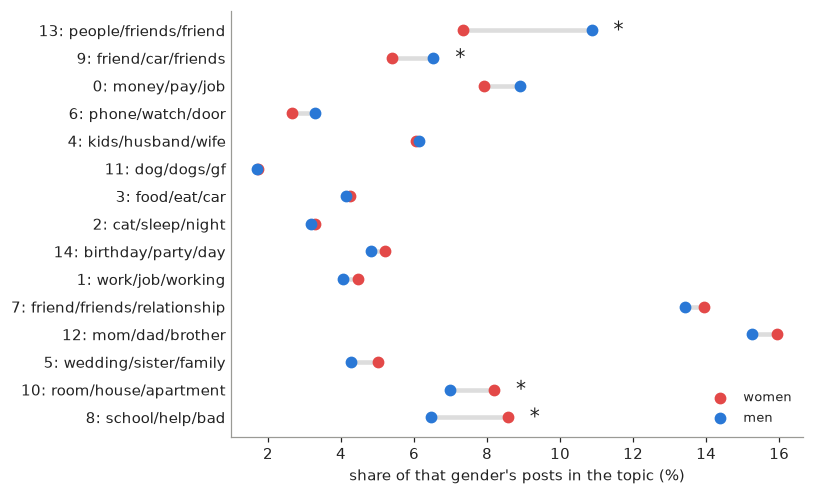

In [7]:
plots.topic_mix(mix)

**what it shows.** (h1) men and women write about somewhat different things, but mostly the same things. four topics differ after correction: men write more about the people/friends/friend topic (about 11% of men's posts against 7% of women's) and the friend/car/friends topic, while women write more about the school/help/bad and room/house/apartment topics. every other topic is within about a point.

the topic mix differs by gender in a statistically clear way, but the effect is small (cramer's v about 0.08, where 0 would mean identical mixes).

### are they judged differently? (h2)

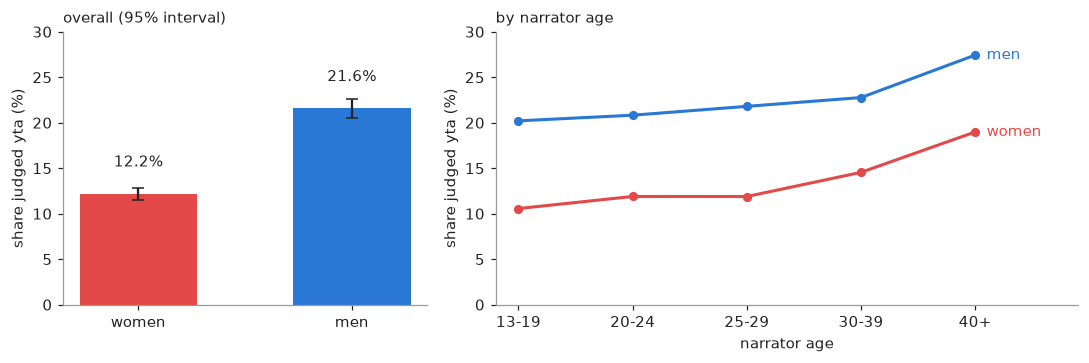

In [8]:
plots.yta_by_gender(pred)

**what it shows.** (h2) the two groups are judged very differently: about 22% of men's posts get yta against 12% of women's, and the intervals are far apart. the difference is about the same size in every age band, from teenagers to people over 40, and both groups get harsher verdicts as narrators get older. age raises yta for everyone but does not explain the difference between genders.

### is that still true within the same topic? (h3)

men and women write about somewhat different things (h1), and topics get different verdicts (h4), so the yta difference could in principle come from men writing about topics that get harsher verdicts. this checks it: the difference in yta rate between men and women inside each topic, with 95% intervals. the grey band is the overall difference. dark dots are significant after the same correction for 15 tests; open grey dots are not.

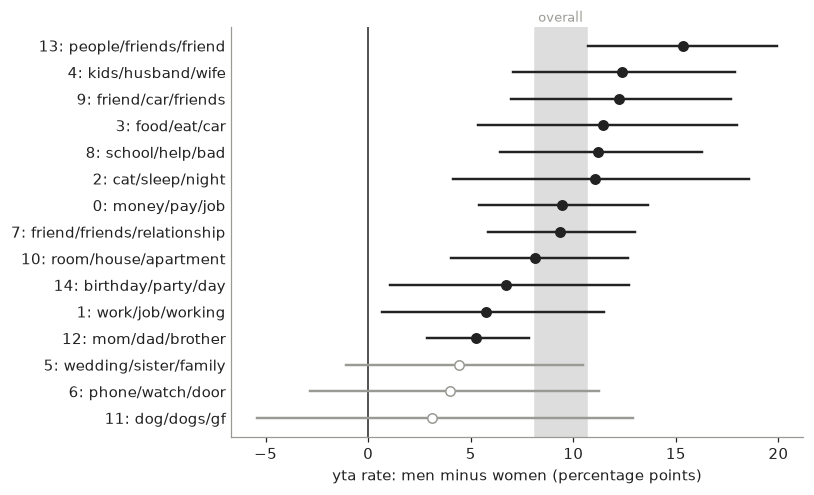

In [9]:
plots.gender_gap_by_topic(verdicts, hyp)

**what it shows.** (h3) the difference appears inside every topic: all 15 dots sit to the right of zero, and 12 are individually significant. the three that are not (dog/dogs/gf, phone/watch/door, wedding/sister/family) have the smallest differences, 3 to 4 points, and dog/dogs/gf has the fewest posts and the widest interval. the gender difference in verdicts is therefore not an artefact of men and women writing about different subjects.

the analysis does not test whether the size of the difference varies by topic. with samples this small, much of the spread between rows is probably noise, so single topics should be read with caution.

In [10]:
out = hyp.copy()
out[['estimate', 'ci_low', 'ci_high']] = out[['estimate', 'ci_low', 'ci_high']].round(3)
out['p'] = out.p.apply(lambda p: '<0.001' if p < .001 else f'{p:.3f}')
out

,id,hypothesis,test,estimate,ci_low,ci_high,p
0,h1,men and women write about different topics,"chi-square, 14 df; estimate is cramer's v",0.082,NaN,NaN,<0.001
1,h2,men and women get yta at different rates,"difference in yta rate, men minus women",0.094,0.081,0.106,<0.001
2,h3,the yta difference remains after controlling for topic,"odds ratio, men vs women, same topic",1.950,1.785,2.130,<0.001
3,h4,yta rates differ across topics,"chi-square, 14 df; estimate is cramer's v",0.120,NaN,NaN,<0.001


**reading the table.**

- **h1 supported.** the topic mix differs between men and women (p < 0.001), but the effect is small (cramer's v about 0.08).
- **h2 supported.** men's yta rate differs from women's by about 9 percentage points (interval 8 to 11; men are higher).
- **h3 supported.** within the same topic, men have nearly twice the odds of a yta verdict (odds ratio about 1.9, interval 1.8 to 2.1). controlling for topic does not shrink the difference.
- **h4 supported.** topics differ clearly in how often they end in yta (p < 0.001, cramer's v about 0.12).

men and women write about slightly different things and are judged quite differently, and the difference in judgment is not explained by what they write about.

## 4. where the classifier goes wrong

the model gives each post a probability of yta, and anything above 0.5 counts as a yta prediction. there are two kinds of mistake:

- **false positive:** the verdict was nta, the model predicted yta
- **false negative:** the verdict was yta, the model predicted nta

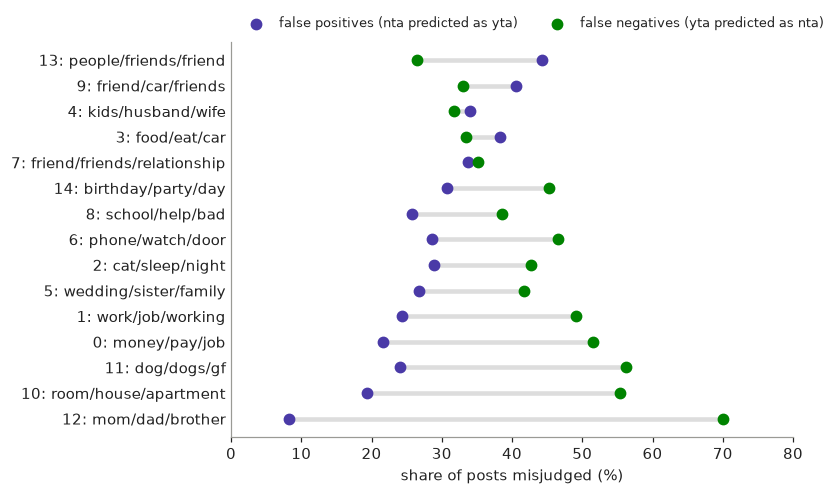

In [11]:
plots.errors_by_topic(by_topic)

**what it shows.** the model follows each topic's usual outcome. in the mom/dad/brother topic, where yta is rarest (10%), it seldom predicts yta: it misses 70% of the yta posts but wrongly flags only 8% of the nta ones. in the people/friends/friend topic, where yta is most common (27%), it does the reverse: about 44% false positives and only 27% false negatives. accuracy is highest (86% for mom/dad/brother) where yta is rarest, which partly reflects the base rate and not a better reading of the story.

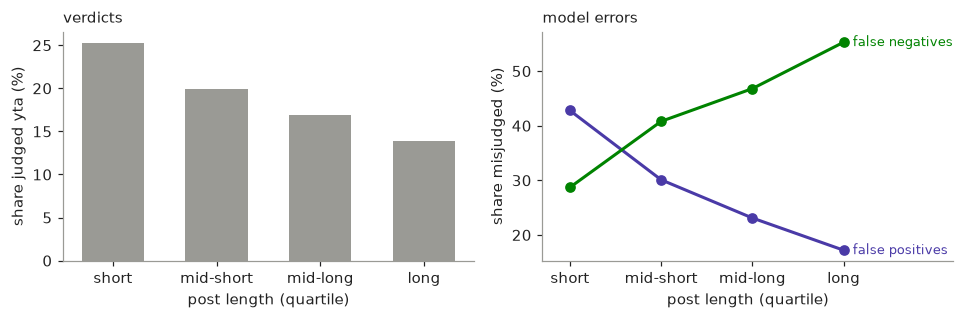

In [12]:
plots.by_length(by_length)

**what it shows.** length is informative in itself. short posts get yta about 25% of the time and long posts about 14%, and the model picks this up: it over-predicts yta on short posts and under-predicts it on long ones. whether this reflects something real (long, detailed stories get more sympathy) or only how people write cannot be settled with this data.

the ten posts the model got wrong with the most confidence:

In [13]:
read('errors.csv')[['verdict', 'p', 'topic_name', 'title']].head(10)

,verdict,p,topic_name,title
0,nta,0.961543,7: friend/friends/relationship,aita for telling off a friend for her obsession with our other friend's girl...
1,yta,0.039718,10: room/house/apartment,aita for not wanting to move out despite being evicted?
2,nta,0.950850,13: people/friends/friend,aita for believe that physical attractiveness is a strong component in a suc...
3,nta,0.950538,8: school/help/bad,aita for trying to convince my wife to not go on a diet?
4,yta,0.059978,12: mom/dad/brother,aita for not telling my aunt that my dad died until a couple of days later?
5,yta,0.060756,8: school/help/bad,aita for not helping my mom out after she insulted me?
6,nta,0.938676,13: people/friends/friend,aita for telling this joke:
7,nta,0.937709,4: kids/husband/wife,aita for not letting my daughter's gf spend the night?
8,nta,0.936755,5: wedding/sister/family,aita for pulling a prank on my wife by fake tattooing my son?
9,nta,0.936370,4: kids/husband/wife,aita for ungrounding my daughter after my wife grounded her?


## limits

- the label is what commenters voted, not moral truth. a gender difference means the crowd judges men's posts more harshly, not that men behave worse.
- gender and age are only known where narrators chose to state them (about a third of posts), and only the two genders they tag.
- the topic model is unsupervised and its topics overlap (several of them are about friends). topic names are therefore approximate descriptions, not clean categories.
- the sentence-embedding model reads only the first part of each post.
- results come from one random sample of 50,000 posts. the full set of 250,487 posts would narrow the intervals, especially for the small topics.